Tes Segmentasi Gambar

d0004 (1).jpg: kandidat mentah=9, baris valid=3, segmen karakter=89
  segmen per baris: min=20, maks=46, rata-rata=29.7


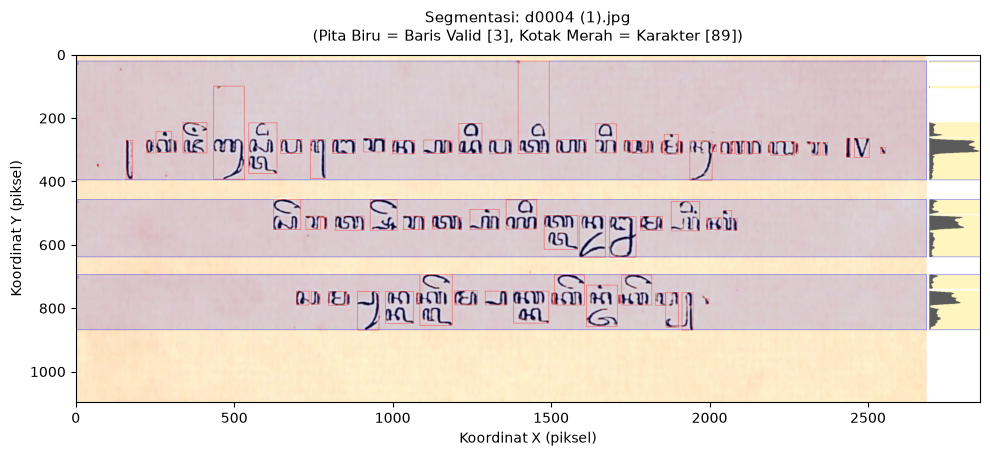

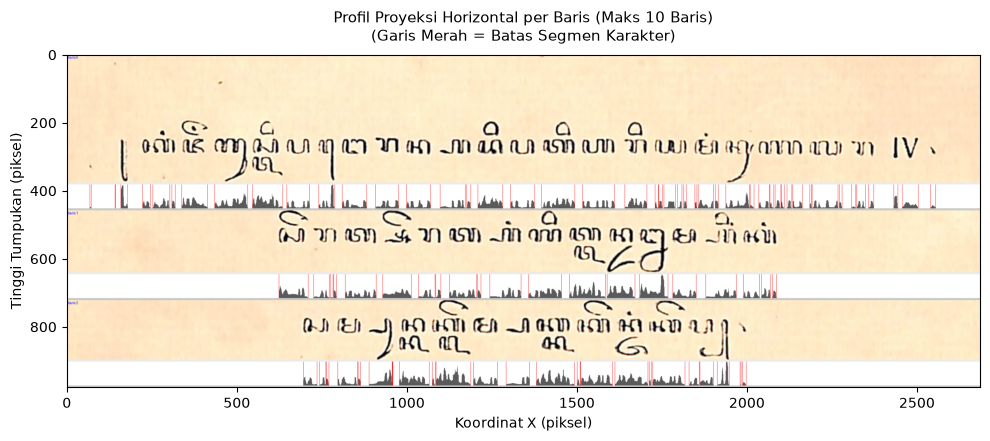

In [1]:
#!/usr/bin/env python3
"""
Verifikasi visual segmentasi projection profile (baris + karakter).
Menampilkan hasil sebagai plot Matplotlib interaktif (bisa zoom & cek koordinat).
"""
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

from javanese_ocr import binarize, runs, segment_chars, segment_lines

HIST_W = 160     # lebar panel profil vertikal
STRIP_H = 70     # tinggi panel profil horizontal per baris


def vertical_profile_panel(proj, raw_cands, lines, width=HIST_W):
    h = len(proj)
    img = Image.new("RGB", (width, h), "white")
    d = ImageDraw.Draw(img)
    for s, e in raw_cands:
        d.rectangle([0, s, width, e - 1], fill=(255, 245, 190))
    m = max(int(proj.max()), 1)
    for y, v in enumerate(proj):
        if v > 0:
            d.line([(0, y), (int(v / m * (width - 1)), y)], fill=(90, 90, 90))
    for s, e in lines:
        d.line([(0, s), (width, s)], fill=(0, 0, 255))
        d.line([(0, e - 1), (width, e - 1)], fill=(0, 0, 255))
    return img


def page_overlay(img, lines, segs):
    base = img.convert("RGBA")
    layer = Image.new("RGBA", base.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(layer)
    for ln, (y0, y1) in enumerate(lines):
        d.rectangle([0, y0, base.width - 1, y1 - 1],
                    fill=(0, 0, 255, 35), outline=(0, 0, 255, 255))
        d.text((4, y0 + 2), str(ln), fill=(0, 0, 255, 255))
    for s in segs:
        d.rectangle([s.x, s.y, s.x + s.w, s.y + s.h], outline=(255, 0, 0, 255))
    return Image.alpha_composite(base, layer).convert("RGB")


def horizontal_profile_panel(hproj, width, height=STRIP_H):
    img = Image.new("RGB", (width, height), "white")
    d = ImageDraw.Draw(img)
    m = max(int(hproj.max()), 1)
    for x, v in enumerate(hproj):
        if v > 0:
            d.line([(x, height - 1), (x, height - 1 - int(v / m * (height - 1)))],
                   fill=(90, 90, 90))
    for x0, x1 in runs(hproj):
        d.line([(x0, 0), (x0, height)], fill=(255, 0, 0))
        d.line([(x1, 0), (x1, height)], fill=(255, 0, 0))
    return img


def line_profile_sheet(img_rgb, bw, lines):
    W = img_rgb.width
    gap = 6
    parts = []
    for ln, (y0, y1) in enumerate(lines):
        crop = img_rgb.crop((0, y0, W, y1))
        prof = horizontal_profile_panel(bw[y0:y1].sum(axis=0), W)
        part = Image.new("RGB", (W, crop.height + prof.height + gap), (235, 235, 235))
        part.paste(crop, (0, 0))
        part.paste(prof, (0, crop.height + gap))
        ImageDraw.Draw(part).text((4, 2), f"baris {ln}", fill=(0, 0, 255))
        parts.append(part)
    if not parts:
        return None
    sheet = Image.new("RGB", (W, sum(p.height for p in parts) + gap * len(parts)),
                      (200, 200, 200))
    y = 0
    for p in parts:
        sheet.paste(p, (0, y))
        y += p.height + gap
    return sheet


def build_images(path, threshold=160, line_profiles=True, max_lines=0):
    """Hitung segmentasi lalu kembalikan (gambar_utama, gambar_profil_baris|None, statistik)."""
    img = Image.open(path).convert("RGB")
    bw = binarize(img, threshold)
    proj = bw.sum(axis=1)
    raw = runs(proj)
    lines = segment_lines(bw)
    segs = segment_chars(bw, lines)

    overlay = page_overlay(img, lines, segs)
    panel = vertical_profile_panel(proj, raw, lines)
    canvas = Image.new("RGB", (overlay.width + 8 + panel.width, overlay.height), "white")
    canvas.paste(overlay, (0, 0))
    canvas.paste(panel, (overlay.width + 8, 0))

    sheet = None
    if line_profiles:
        shown = lines[:max_lines] if max_lines else lines
        sheet = line_profile_sheet(img, bw, shown)

    per_line = [sum(1 for s in segs if s.line == i) for i in range(len(lines))]
    stats = dict(raw_candidates=len(raw), lines=len(lines), chars=len(segs),
                 per_line=per_line)
    return canvas, sheet, stats


def _print_stats(path, st):
    print(f"{path}: kandidat mentah={st['raw_candidates']}, baris valid={st['lines']}, "
          f"segmen karakter={st['chars']}")
    if st["per_line"]:
        pl = st["per_line"]
        print(f"  segmen per baris: min={min(pl)}, maks={max(pl)}, "
              f"rata-rata={np.mean(pl):.1f}")


def plot_segmentation(path, threshold=160, line_profiles=True, max_lines=10,
                      out=None, tampilkan_sumbu=True):
    """Menampilkan hasil segmentasi sebagai plot Matplotlib."""
    canvas, sheet, st = build_images(path, threshold, line_profiles, max_lines)
    _print_stats(path, st)

    # 1. Plot Gambar Segmentasi Utama + Profil Vertikal
    fig1, ax1 = plt.subplots(figsize=(10, 12))
    ax1.imshow(np.asarray(canvas))
    ax1.set_title(
        f"Segmentasi: {Path(path).name}\n"
        f"(Pita Biru = Baris Valid [{st['lines']}], Kotak Merah = Karakter [{st['chars']}])",
        fontsize=11, pad=10
    )
    if tampilkan_sumbu:
        ax1.set_xlabel("Koordinat X (piksel)")
        ax1.set_ylabel("Koordinat Y (piksel)")
    else:
        ax1.axis("off")
    plt.tight_layout()

    # 2. Plot Profil Proyeksi Horizontal per Baris (jika aktif)
    if sheet is not None:
        fig2, ax2 = plt.subplots(figsize=(10, 10))
        ax2.imshow(np.asarray(sheet))
        ax2.set_title(
            f"Profil Proyeksi Horizontal per Baris (Maks {max_lines if max_lines else 'Semua'} Baris)\n"
            "(Garis Merah = Batas Segmen Karakter)",
            fontsize=11, pad=10
        )
        if tampilkan_sumbu:
            ax2.set_xlabel("Koordinat X (piksel)")
            ax2.set_ylabel("Tinggi Tumpukan (piksel)")
        else:
            ax2.axis("off")
        plt.tight_layout()

    # 3. Simpan ke folder jika parameter 'out' diisi
    if out:
        outdir = Path(out)
        outdir.mkdir(parents=True, exist_ok=True)
        stem = Path(path).stem
        canvas.save(outdir / f"{stem}_segmentation.png")
        if sheet is not None:
            sheet.save(outdir / f"{stem}_line_profiles.png")
        print(f"  -> File resolusi penuh tersimpan di folder: {outdir}")

    # Tampilkan semua jendela plot
    plt.show()


# =====================================================================
# PENGATURAN & EKSEKUSI LANGSUNG (Klik tombol Run)
# =====================================================================
if __name__ == "__main__":
    GAMBAR_TARGET = "d0004 (1).jpg"
    
    THRESHOLD = 160
    TAMPILKAN_PROFIL_BARIS = True
    MAKS_BARIS_PROFIL = 10         # Ubah ke 0 jika ingin menampilkan semua baris
    FOLDER_SIMPAN = None           # Ganti dengan "seg_check" jika ingin sekalian menyimpan file
    TAMPILKAN_KOORDINAT_SUMBU = True

    if Path(GAMBAR_TARGET).exists():
        plot_segmentation(
            path=GAMBAR_TARGET,
            threshold=THRESHOLD,
            line_profiles=TAMPILKAN_PROFIL_BARIS,
            max_lines=MAKS_BARIS_PROFIL,
            out=FOLDER_SIMPAN,
            tampilkan_sumbu=TAMPILKAN_KOORDINAT_SUMBU
        )
    else:
        print(f"[Error] File '{GAMBAR_TARGET}' tidak ditemukan.")